# ReviewLens - Fine-tuned BERT (Longqi Sun)

Fine-tunes `bert-base-uncased` for three-class sentiment classification on the team's fixed shared split. It evaluates on the held-out test set and on the 600 AI-labeled reviews, then writes results in the same flat Drive format as the other two collaborators.

**Before running**
1. In Colab, choose **Runtime > Change runtime type > GPU**.
2. Put `train.csv`, `val.csv`, `test.csv`, and `ai_labeled_600.csv` in `MyDrive/NLP/Final_Project/`.
3. Run all cells. Outputs are written to `MyDrive/NLP/Final_Project/longqi_bert/`.

The notebook never changes the shared CSV files. It trains only on `train.csv`, selects the best epoch using validation macro-F1, and touches the test set only after training is complete.

In [1]:
!pip -q install -U "pyarrow>=19,<24" transformers datasets accelerate huggingface_hub

## 1. Setup and reproducibility

In [2]:
import inspect
import json
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from google.colab import drive
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/NLP/Final_Project')
DATA = ROOT if (ROOT / 'train.csv').exists() else ROOT / 'shared_data'
OUT = ROOT / 'longqi_bert'
CHECKPOINT_DIR = OUT / 'checkpoints'
FINAL_MODEL_DIR = OUT / 'best_model'
OUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = 'bert-base-uncased'
LABELS = ['Negative', 'Neutral', 'Positive']
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}
SEED = 42
MAX_LENGTH = 384
LEARNING_RATE = 2e-5
EPOCHS = 3
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 1
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
TIMING_BATCH_SIZE = EVAL_BATCH_SIZE

if not torch.cuda.is_available():
    raise RuntimeError('A GPU runtime is required. In Colab select Runtime > Change runtime type > GPU.')
GPU = torch.cuda.get_device_name(0)
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

print('GPU:', GPU)
print('Data:', DATA)
print('Output:', OUT)
print('Effective train batch size:', TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4
Data: /content/drive/MyDrive/NLP/Final_Project
Output: /content/drive/MyDrive/NLP/Final_Project/longqi_bert
Effective train batch size: 16


## 2. Load and verify the fixed shared data

In [3]:
required_files = ['train.csv', 'val.csv', 'test.csv', 'ai_labeled_600.csv']
missing = [name for name in required_files if not (DATA / name).exists()]
if missing:
    raise FileNotFoundError(f'Missing files in {DATA}: {missing}')

train_df = pd.read_csv(DATA / 'train.csv')
val_df = pd.read_csv(DATA / 'val.csv')
test_df = pd.read_csv(DATA / 'test.csv')
exp2_df = pd.read_csv(DATA / 'ai_labeled_600.csv')

expected_main = {'review_id', 'label', 'text'}
for name, df, expected_n in [
    ('train', train_df, 40000),
    ('val', val_df, 5000),
    ('test', test_df, 5000),
]:
    assert expected_main.issubset(df.columns), f'{name}: missing required columns'
    assert len(df) == expected_n, f'{name}: expected {expected_n}, found {len(df)}'
    assert set(df.label) == set(LABELS), f'{name}: unexpected labels {set(df.label)}'
    assert df.review_id.is_unique, f'{name}: duplicate review_id'
    assert df.text.notna().all(), f'{name}: missing text'

assert {'review_id', 'text', 'ai_label', 'star_label'}.issubset(exp2_df.columns)
assert len(exp2_df) == 600 and exp2_df.review_id.is_unique
assert set(exp2_df.ai_label).issubset(LABELS)
assert set(exp2_df.star_label).issubset(LABELS)

main_ids = [set(train_df.review_id), set(val_df.review_id), set(test_df.review_id)]
assert main_ids[0].isdisjoint(main_ids[1])
assert main_ids[0].isdisjoint(main_ids[2])
assert main_ids[1].isdisjoint(main_ids[2])
assert set(exp2_df.review_id).isdisjoint(set().union(*main_ids))

for name, df, label_col in [
    ('train', train_df, 'label'),
    ('val', val_df, 'label'),
    ('test', test_df, 'label'),
    ('exp2 star', exp2_df, 'star_label'),
    ('exp2 AI', exp2_df, 'ai_label'),
]:
    print(name, len(df), df[label_col].value_counts().reindex(LABELS).to_dict())

train 40000 {'Negative': 13333, 'Neutral': 13334, 'Positive': 13333}
val 5000 {'Negative': 1667, 'Neutral': 1666, 'Positive': 1667}
test 5000 {'Negative': 1667, 'Neutral': 1667, 'Positive': 1666}
exp2 star 600 {'Negative': 200, 'Neutral': 200, 'Positive': 200}
exp2 AI 600 {'Negative': 260, 'Neutral': 169, 'Positive': 171}


## 3. Token length check and dataset encoding

`MAX_LENGTH=384` is the fixed experiment setting. The table below records how many training reviews are longer than 256, 384, and BERT's 512-token limit. Dynamic padding is used within each batch.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

def token_lengths(texts, batch_size=512):
    lengths = []
    texts = list(texts)
    for start in range(0, len(texts), batch_size):
        encoded = tokenizer(
            texts[start:start + batch_size],
            add_special_tokens=True,
            truncation=False,
            padding=False,
            return_length=True,
        )
        lengths.extend(encoded['length'])
    return np.asarray(lengths)

train_token_lengths = token_lengths(train_df.text.astype(str))
length_summary = pd.DataFrame([{
    'n': len(train_token_lengths),
    'mean_tokens': train_token_lengths.mean(),
    'median_tokens': np.median(train_token_lengths),
    'p95_tokens': np.percentile(train_token_lengths, 95),
    'max_tokens': train_token_lengths.max(),
    'pct_over_256': 100 * np.mean(train_token_lengths > 256),
    'pct_over_384': 100 * np.mean(train_token_lengths > 384),
    'pct_over_512': 100 * np.mean(train_token_lengths > 512),
    'selected_max_length': MAX_LENGTH,
}])
length_summary.to_csv(OUT / 'token_length_summary.csv', index=False)
display(length_summary.round(3))

def make_labeled_dataset(df, label_col='label'):
    frame = pd.DataFrame({
        'text': df.text.astype(str),
        'labels': df[label_col].map(LABEL2ID).astype(int),
    })
    return Dataset.from_pandas(frame, preserve_index=False)

def make_inference_dataset(df):
    return Dataset.from_pandas(
        pd.DataFrame({'text': df.text.astype(str)}),
        preserve_index=False,
    )

def tokenize_batch(batch):
    return tokenizer(
        batch['text'],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )

train_ds = make_labeled_dataset(train_df).map(tokenize_batch, batched=True, remove_columns=['text'])
val_ds = make_labeled_dataset(val_df).map(tokenize_batch, batched=True, remove_columns=['text'])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
print(train_ds, val_ds)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (621 > 512). Running this sequence through the model will result in indexing errors


,n,mean_tokens,median_tokens,p95_tokens,max_tokens,pct_over_256,pct_over_384,pct_over_512,selected_max_length
0,40000,181.824,163.0,307.0,621,12.262,0.18,0.008,384


Map:   0%|          | 0/40000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 40000
}) Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 5000
})


## 4. Metrics and trainer

Macro-F1 is the model-selection metric because it weights Negative, Neutral, and Positive equally.

In [6]:
def metrics_row(setting, gold, pred):
    gold, pred = list(gold), list(pred)
    row = {
        'setting': setting,
        'n': len(gold),
        'accuracy': accuracy_score(gold, pred),
    }
    for avg in ('macro', 'micro'):
        p, r, f, _ = precision_recall_fscore_support(
            gold, pred, labels=LABELS, average=avg, zero_division=0
        )
        row.update({
            f'{avg}_precision': p,
            f'{avg}_recall': r,
            f'{avg}_f1': f,
        })
    row['invalid_rate'] = sum(p == 'Invalid' for p in pred) / len(pred)
    p, r, f, support = precision_recall_fscore_support(
        gold, pred, labels=LABELS, zero_division=0
    )
    for i, label in enumerate(LABELS):
        row.update({
            f'{label}_precision': p[i],
            f'{label}_recall': r[i],
            f'{label}_f1': f[i],
            f'{label}_support': int(support[i]),
        })
    return row

def compute_metrics(eval_prediction):
    logits, label_ids = eval_prediction
    if isinstance(logits, tuple):
        logits = logits[0]
    pred_ids = np.argmax(logits, axis=-1)
    gold = [ID2LABEL[int(i)] for i in label_ids]
    pred = [ID2LABEL[int(i)] for i in pred_ids]
    row = metrics_row('validation', gold, pred)
    return {k: v for k, v in row.items() if k not in {'setting', 'n'}}

training_kwargs = dict(
    output_dir=str(CHECKPOINT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    num_train_epochs=EPOCHS,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=750,
    save_strategy='epoch',
    logging_strategy='steps',
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    save_total_limit=2,
    report_to='none',
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=2,
    fp16=not torch.cuda.is_bf16_supported(),
    bf16=torch.cuda.is_bf16_supported(),
)
ta_parameters = inspect.signature(TrainingArguments.__init__).parameters
if 'eval_strategy' in ta_parameters:
    training_kwargs['eval_strategy'] = 'epoch'
else:
    training_kwargs['evaluation_strategy'] = 'epoch'
training_args = TrainingArguments(**training_kwargs)

def build_trainer(model):
    kwargs = dict(
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )
    trainer_parameters = inspect.signature(Trainer.__init__).parameters
    if 'processing_class' in trainer_parameters:
        kwargs['processing_class'] = tokenizer
    else:
        kwargs['tokenizer'] = tokenizer
    return Trainer(**kwargs)

## 5. Train or reload the completed model

Checkpoints are kept in Drive. If a run is interrupted, rerunning the notebook resumes from the latest checkpoint. If `best_model/` already exists, training is skipped.

In [7]:
train_info_path = OUT / 'train_info.json'

if (FINAL_MODEL_DIR / 'config.json').exists():
    print('Loading completed model from', FINAL_MODEL_DIR)
    model = AutoModelForSequenceClassification.from_pretrained(FINAL_MODEL_DIR)
    trainer = build_trainer(model)
    train_info = json.loads(train_info_path.read_text()) if train_info_path.exists() else {}
else:
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(LABELS),
        label2id=LABEL2ID,
        id2label=ID2LABEL,
    )
    trainer = build_trainer(model)
    last_checkpoint = get_last_checkpoint(str(CHECKPOINT_DIR))
    print('Resume checkpoint:', last_checkpoint)
    torch.cuda.synchronize()
    train_start = time.perf_counter()
    train_output = trainer.train(resume_from_checkpoint=last_checkpoint)
    torch.cuda.synchronize()
    training_minutes = (time.perf_counter() - train_start) / 60
    trainer.save_model(FINAL_MODEL_DIR)
    tokenizer.save_pretrained(FINAL_MODEL_DIR)
    pd.DataFrame(trainer.state.log_history).to_csv(OUT / 'training_history.csv', index=False)
    train_info = {
        'model': MODEL_NAME,
        'gpu': GPU,
        'seed': SEED,
        'train_n': len(train_df),
        'val_n': len(val_df),
        'epochs': EPOCHS,
        'learning_rate': LEARNING_RATE,
        'train_batch_size': TRAIN_BATCH_SIZE,
        'gradient_accumulation_steps': GRADIENT_ACCUMULATION_STEPS,
        'effective_train_batch_size': TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS,
        'eval_batch_size': EVAL_BATCH_SIZE,
        'max_length': MAX_LENGTH,
        'weight_decay': WEIGHT_DECAY,
        'warmup_ratio': WARMUP_RATIO,
        'training_minutes': training_minutes,
        'best_checkpoint': trainer.state.best_model_checkpoint,
        'best_validation_macro_f1': trainer.state.best_metric,
        'resumed_from_checkpoint': last_checkpoint,
    }
    train_info_path.write_text(json.dumps(train_info, indent=2))

display(pd.Series(train_info, name='value').to_frame())

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Resume checkpoint: None


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro Precision,Micro Recall,Micro F1,Invalid Rate,Negative Precision,Negative Recall,Negative F1,Negative Support,Neutral Precision,Neutral Recall,Neutral F1,Neutral Support,Positive Precision,Positive Recall,Positive F1,Positive Support
1,0.520604,0.534184,0.772400,0.774855,0.772357,0.766130,0.772400,0.772400,0.772400,0.000000,0.707056,0.871626,0.780763,1667,0.749196,0.559424,0.640550,1666,0.868313,0.886023,0.877078,1667
2,0.439294,0.511848,0.792600,0.791146,0.792579,0.791750,0.792600,0.792600,0.792600,0.000000,0.790780,0.802639,0.796666,1667,0.710379,0.686074,0.698015,1666,0.872278,0.889022,0.880570,1667
3,0.294897,0.585927,0.795200,0.797307,0.795184,0.796102,0.795200,0.795200,0.795200,0.000000,0.795238,0.801440,0.798327,1667,0.697430,0.716687,0.706927,1666,0.899254,0.867427,0.883053,1667


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,value
model,bert-base-uncased
gpu,NVIDIA L4
seed,42
train_n,40000
val_n,5000
epochs,3
learning_rate,0.00002
train_batch_size,16
gradient_accumulation_steps,1
effective_train_batch_size,16


## 6. Validation, test, and Experiment 2 predictions

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Validation accuracy=0.7952, macro-F1=0.7961


Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

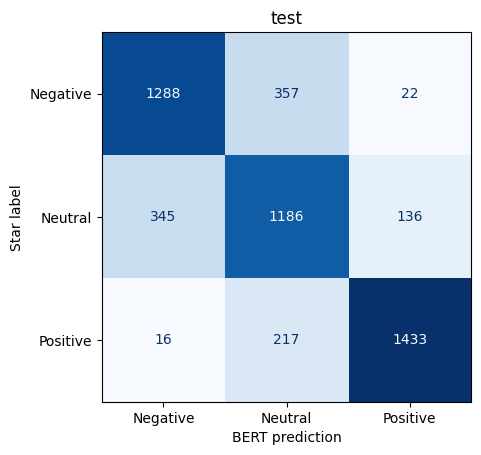

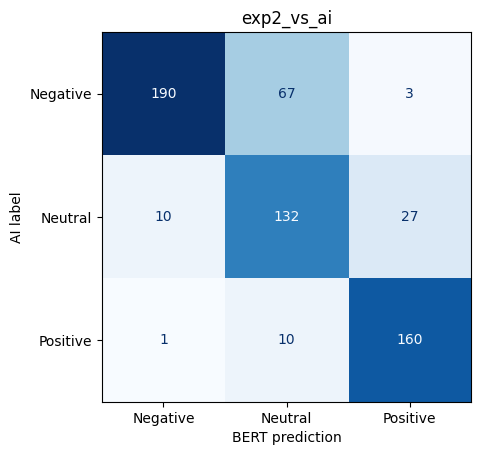

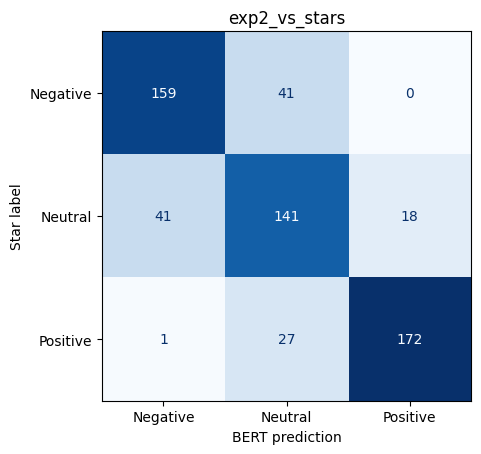

setting,BERT — val,BERT — test,BERT — Exp2 vs AI labels,BERT — Exp2 vs star labels (same 600)
n,5000.000000,5000.000000,600.000000,600.000000
accuracy,0.795200,0.781400,0.803333,0.786667
macro_precision,0.797307,0.785211,0.806319,0.790316
macro_recall,0.795184,0.781416,0.815836,0.786667
macro_f1,0.796102,0.782980,0.803045,0.788185
micro_precision,0.795200,0.781400,0.803333,0.786667
micro_recall,0.795200,0.781400,0.803333,0.786667
micro_f1,0.795200,0.781400,0.803333,0.786667
invalid_rate,0.000000,0.000000,0.000000,0.000000
Negative_precision,0.795238,0.781079,0.945274,0.791045


In [8]:
import matplotlib.pyplot as plt

def encoded_inference_dataset(df):
    return make_inference_dataset(df).map(
        tokenize_batch, batched=True, remove_columns=['text']
    )

def predict_dataframe(df, name):
    prediction = trainer.predict(encoded_inference_dataset(df))
    logits = prediction.predictions[0] if isinstance(prediction.predictions, tuple) else prediction.predictions
    pred_ids = np.argmax(logits, axis=-1)
    pred_labels = np.asarray([ID2LABEL[int(i)] for i in pred_ids])
    pd.DataFrame({
        'review_id': df.review_id.to_numpy(),
        'pred': pred_labels,
    }).to_csv(OUT / f'preds_{name}.csv', index=False)
    return pred_labels

def save_cm(name, gold, pred, gold_name):
    cm = confusion_matrix(gold, pred, labels=LABELS)
    pd.DataFrame(
        cm,
        index=pd.Index(LABELS, name=gold_name),
        columns=LABELS,
    ).to_csv(OUT / f'cm_{name}.csv')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', colorbar=False)
    plt.ylabel(gold_name)
    plt.xlabel('BERT prediction')
    plt.title(name)
    plt.savefig(OUT / f'cm_{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

val_pred = predict_dataframe(val_df, 'val')
val_row = metrics_row('BERT — val', val_df.label, val_pred)
print(f"Validation accuracy={val_row['accuracy']:.4f}, macro-F1={val_row['macro_f1']:.4f}")

# The held-out test set is evaluated only after training and validation are complete.
test_pred = predict_dataframe(test_df, 'test')
exp2_pred = predict_dataframe(exp2_df, 'exp2')

rows = [
    val_row,
    metrics_row('BERT — test', test_df.label, test_pred),
    metrics_row('BERT — Exp2 vs AI labels', exp2_df.ai_label, exp2_pred),
    metrics_row('BERT — Exp2 vs star labels (same 600)', exp2_df.star_label, exp2_pred),
]
results = pd.DataFrame(rows)
results.to_csv(OUT / 'results_summary.csv', index=False)

save_cm('test', test_df.label, test_pred, 'Star label')
save_cm('exp2_vs_ai', exp2_df.ai_label, exp2_pred, 'AI label')
save_cm('exp2_vs_stars', exp2_df.star_label, exp2_pred, 'Star label')

display(results.set_index('setting').T)

## 7. Inference cost

For consistency with the collaborators, inference is timed on 300 test reviews (100 per class) after an untimed warm-up batch.

In [9]:
timing_df = pd.concat([
    group.sample(n=100, random_state=SEED)
    for _, group in test_df.groupby('label')
]).sample(frac=1, random_state=SEED).reset_index(drop=True)
timing_ds = encoded_inference_dataset(timing_df)
warmup_ds = timing_ds.select(range(min(TIMING_BATCH_SIZE, len(timing_ds))))
trainer.predict(warmup_ds)
torch.cuda.synchronize()
timing_start = time.perf_counter()
trainer.predict(timing_ds)
torch.cuda.synchronize()
sec_per_review = (time.perf_counter() - timing_start) / len(timing_ds)

cost = pd.DataFrame([{
    'setting': 'BERT',
    'gpu_inference': GPU,
    'batch_size': EVAL_BATCH_SIZE,
    'timed_reviews': len(timing_ds),
    'sec_per_review': sec_per_review,
    'reviews_per_sec': 1 / sec_per_review,
    'gpu_training': train_info.get('gpu', GPU),
    'training_minutes': train_info.get('training_minutes', np.nan),
    'train_n': train_info.get('train_n', len(train_df)),
    'epochs': train_info.get('epochs', EPOCHS),
}])
cost.to_csv(OUT / 'inference_cost.csv', index=False)
display(cost)

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

,setting,gpu_inference,batch_size,timed_reviews,sec_per_review,reviews_per_sec,gpu_training,training_minutes,train_n,epochs
0,BERT,NVIDIA L4,32,300,0.002946,339.420997,NVIDIA L4,16.890988,40000,3


## 8. Output manifest

The Drive folder is intentionally flat, matching the collaborators' Colab output pattern. When committing to GitHub, place `results_summary.csv`, `inference_cost.csv`, and `cm_*.csv` under `results/`; `preds_*.csv` under `outputs/`; and `cm_*.png` under `figures/`. Keep this executed notebook at the top of `longqi_bert/`. Do not commit `checkpoints/` or `best_model/`.

In [10]:
expected_outputs = [
    'results_summary.csv',
    'inference_cost.csv',
    'preds_val.csv',
    'preds_test.csv',
    'preds_exp2.csv',
    'cm_test.csv',
    'cm_test.png',
    'cm_exp2_vs_ai.csv',
    'cm_exp2_vs_ai.png',
    'cm_exp2_vs_stars.csv',
    'cm_exp2_vs_stars.png',
    'token_length_summary.csv',
    'training_history.csv',
    'train_info.json',
]
manifest = []
for name in expected_outputs:
    path = OUT / name
    manifest.append({
        'file': name,
        'exists': path.exists(),
        'size_bytes': path.stat().st_size if path.exists() else None,
    })
manifest_df = pd.DataFrame(manifest)
display(manifest_df)
assert manifest_df.exists.all(), 'One or more expected output files are missing.'
print('Complete. Outputs saved to:', OUT)

,file,exists,size_bytes
0,results_summary.csv,True,1550
1,inference_cost.csv,True,222
2,preds_val.csv,True,128303
3,preds_test.csv,True,128255
4,preds_exp2.csv,True,15406
5,cm_test.csv,True,100
6,cm_test.png,True,31584
7,cm_exp2_vs_ai.csv,True,89
8,cm_exp2_vs_ai.png,True,29243
9,cm_exp2_vs_stars.csv,True,91


Complete. Outputs saved to: /content/drive/MyDrive/NLP/Final_Project/longqi_bert
